# 📑 Caso: Análisis de transacciones financieras (5 pts)

### Contexto
El área de prevención de fraudes de un banco analiza un conjunto de **transacciones financieras** para identificar patrones de **lavado de dinero (AML)**.  

En el dataset, la variable **`Is_laundering`** indica si una transacción ha sido clasificada como sospechosa de lavado de dinero (**1 = sospechosa**, **0 = normal**). El banco quiere entender si los **montos de las transacciones (`Amount`)** y los **tipos de pago (`Payment_type`)** están relacionados con operaciones de lavado.  


---

## Preguntas (Total: 5 puntos)

**1. Montos de transacciones (2 pts)**  
Para la variable `Amount`, calcule la **media, mediana, desviación estándar, asimetría (skewness) y curtosis (kurtosis)**. Luego, represente la distribución de los montos con un **histograma** *(bins = 50)* e interprete la distribución que observa en el gráfico.  

---

**2. Comparación entre transacciones normales y sospechosas (2 pts)**  
Genere un **boxplot** que compare los montos (`Amount`) de las transacciones **normales (`Is_laundering = 0`)** y las **sospechosas (`Is_laundering = 1`)**. Luego, agrupe los datos por `Is_laundering` y obtenga un resumen estadístico de `Amount` usando describe().
- **Tendencia central:** Compare las medianas de ambos grupos.
- **Dispersión:** ¿Qué grupo presenta mayor variabilidad?  
- **Valores atípicos:** ¿Se observan más outliers en alguno de los dos grupos?  

---

**3. Tipo de pago (1 pt)**  
Obtenga la **frecuencia de cada `Payment_type`** en las transacciones sospechosas (`Is_laundering = 1`). Escriba el código necesario e interprete qué tipo de pago aparece con mayor frecuencia en operaciones de lavado.


---

### ℹ️ Nota para el estudiante
En el siguiente bloque ya se realizaron los **primeros pasos**: **carga del dataset**, **inspección inicial** y una **limpieza mínima** (eliminación de duplicados y, opcionalmente, eliminación de filas con nulos).  
A partir del DataFrame **`df`** resultante, **responde las preguntas del caso** en las celdas de código que están más abajo.


In [2]:
# === Bloque base: Carga, inspección inicial y limpieza mínima ===

# Librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

# 1) Carga de datos
df = pd.read_csv("SAML-D.csv")   # Asegúrate de tener el archivo en el mismo directorio
df= df[df["Amount"] <= df["Amount"].quantile(0.995)]
print("Dimensiones del dataset:", df.shape)

# 2) Inspección inicial
print("\nPrimeras filas del dataset:")
display(df.head())

print("\nInformación general:")
print(df.info())

print("\nValores nulos por columna:")
print(df.isnull().sum())

# 3) Limpieza básica
# 3.1) Eliminar duplicados
df = df.drop_duplicates()
print("\nDimensiones después de eliminar duplicados:", df.shape)

# 3.2) (Opcional) Eliminar filas con nulos si afectan el análisis
#     *Puedes comentar esta línea si deseas tratar nulos por columna*
df = df.dropna()
print("Dimensiones después de eliminar filas con nulos:", df.shape)

# El DataFrame limpio queda en la variable df


Dimensiones del dataset: (147920, 12)

Primeras filas del dataset:


,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0.0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0.0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0.0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0.0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0.0,Normal_Cash_Deposits



Información general:
<class 'pandas.core.frame.DataFrame'>
Index: 147920 entries, 0 to 148663
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Time                    147920 non-null  object 
 1   Date                    147920 non-null  object 
 2   Sender_account          147920 non-null  int64  
 3   Receiver_account        147920 non-null  int64  
 4   Amount                  147920 non-null  float64
 5   Payment_currency        147920 non-null  object 
 6   Received_currency       147920 non-null  object 
 7   Sender_bank_location    147920 non-null  object 
 8   Receiver_bank_location  147920 non-null  object 
 9   Payment_type            147920 non-null  object 
 10  Is_laundering           147920 non-null  float64
 11  Laundering_type         147920 non-null  object 
dtypes: float64(2), int64(2), object(8)
memory usage: 14.7+ MB
None

Valores nulos por columna:
Time                

---

### 📌 Espacio para tus respuestas
Usa las siguientes celdas y agrega tus interpretaciones en texto donde corresponda.


### Pregunta 1 - Montos de transacciones (2 pts)

- Para la variable `Amount`, calcule la media, mediana, desviación estándar, asimetría (skewness) y curtosis (kurtosis).

In [8]:
# Estadísticos solicitados
print("Media:", df["Amount"].mean())
print("Mediana:", df["Amount"].median())
print("Desviación estándar:", df["Amount"].std())
print("Asimetría (skewness):", skew(df["Amount"]))
print("Curtosis (kurtosis):", kurtosis(df["Amount"]))

Media: 7533.3385624980265
Mediana: 6095.0
Desviación estándar: 7245.702437697191
Asimetría (skewness): 2.259262705914642
Curtosis (kurtosis): 8.952340625321733


- Represente la distribución de los montos con un histograma con bins = 50.

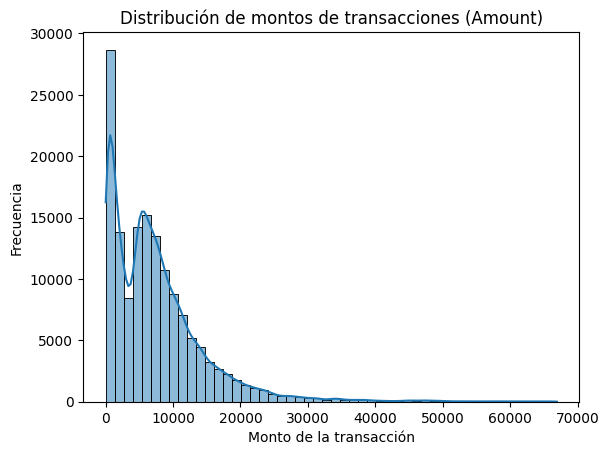

In [9]:
# Histograma
sns.histplot(df["Amount"], bins=50, kde=True)
plt.title("Distribución de montos de transacciones (Amount)")
plt.xlabel("Monto de la transacción")
plt.ylabel("Frecuencia")
plt.show()




- Interprete la distribución que observa en el gráfico.

**Interpretación:**  

### Pregunta 2 - Comparación entre transacciones normales y sospechosas (2 pts)

- Genere un **boxplot** que compare los montos (`Amount`) de las transacciones **normales (`Is_laundering = 0`)** y las **sospechosas (`Is_laundering = 1`)**.

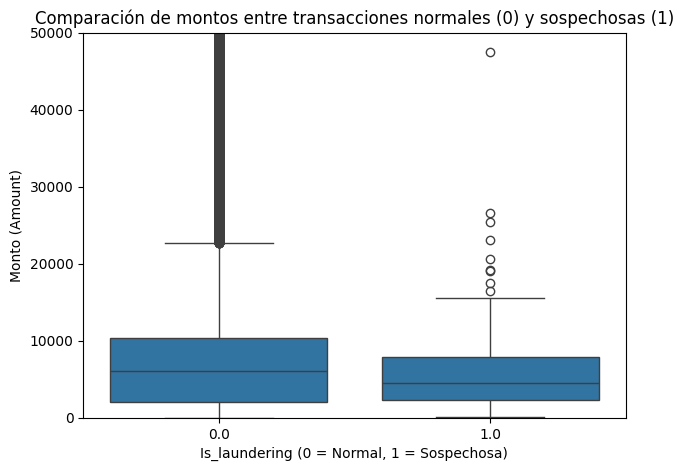

In [6]:
# Boxplot de Amount según Is_laundering
plt.figure(figsize=(7,5))
sns.boxplot(x="Is_laundering", y="Amount", data=df)
plt.title("Comparación de montos entre transacciones normales (0) y sospechosas (1)")
plt.xlabel("Is_laundering (0 = Normal, 1 = Sospechosa)")
plt.ylabel("Monto (Amount)")
plt.ylim(0, 50000)  # limitar eje Y para mejor visualización
plt.show()


- Luego, agrupe los datos por `Is_laundering` y obtenga un resumen estadístico de `Amount` usando describe(). Complete la línea de código con los nombres de las variables correctas.

In [10]:
# Estadísticos comparativos por grupo
print(df.groupby("Is_laundering")["Amount"].describe())

                  count         mean          std    min        25%       50%  \
Is_laundering                                                                   
0.0            147758.0  7534.726599  7245.482589   8.88  2070.5675  6098.235   
1.0               162.0  6267.329227  7357.690203  27.19  2295.7925  4548.010   

                    75%           max  
Is_laundering                          
0.0            10331.07  66891.510000  
1.0             7826.31  61062.758158  


**Tendencia central:** Compare las medianas de ambos grupos.

**Respuesta:**

**Dispersión:** ¿Qué grupo presenta mayor variabilidad?

**Respuesta:**

**Valores atípicos:** ¿Se observan más outliers en alguno de los dos grupos?

**Respuesta:**

### Pregunta 3 - Tipo de pago (1 pt)

Obtenga la frecuencia de cada Payment_type en las transacciones sospechosas (Is_laundering = 1). Escriba el código necesario e interprete qué tipo de pago aparece con mayor frecuencia en operaciones de lavado.


In [7]:
# Solución Pregunta 3

# Filtrar las transacciones sospechosas
df_suspicious = df[df["Is_laundering"] == 1]

# Frecuencia por tipo de pago
print(df_suspicious["Payment_type"].value_counts())


Payment_type
Cross-border       51
Cash Withdrawal    26
Credit card        21
Debit card         19
ACH                17
Cash Deposit       15
Cheque             13
Name: count, dtype: int64


**Frecuencia de `Payment_type` en transacciones sospechosas (`Is_laundering = 1`):**  

**Interpretación:**